# 05 · Explorer playground

A scratch pad for the other notebooks' data. **Change the knobs in the next cell
and re-run the cells below** (Cell → Run All Below). No widgets, no callbacks —
just plain Python values, so the notebook still renders on GitHub with its
outputs attached.

Knobs: `TREE`, `SITES`, `EXTENSIONS`, `MIN_BYTES`, `MAX_BYTES`, `DATE_FROM`,
`DATE_TO`, `STATUS`, `TOP_N`.

In [1]:
import os
import sys

# Make the shared loader importable whether the kernel started in the repo root
# or in notebooks/.
CWD = os.getcwd()
for _cand in (os.path.join(CWD, "notebooks"), CWD, os.path.dirname(CWD)):
    if os.path.isfile(os.path.join(_cand, "dadosabertos_data.py")):
        sys.path.insert(0, _cand)
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import dadosabertos_data as d

plt = d.setup_plots()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)

print("repository root :", d.ROOT)
print("loader module   :", os.path.dirname(d.__file__))
for _t in d.TREES:
    print(f"  {_t:<16} {len(d.site_dirs(_t))} site folders")

repository root : /home/user/dadosabertos
loader module   : /home/user/dadosabertos/notebooks
  outputs          5 site folders
  outputs-replica  6 site folders


In [2]:
# ---------------------------------------------------------------- knobs ----
TREE = "outputs-replica"       # "outputs" (listing inventory) or "outputs-replica" (full run)
SITES = []                     # [] = every site, or e.g. ["dados.cvm.gov.br"]
EXTENSIONS = []                # [] = every type, or e.g. [".zip", ".pdf"]
MIN_BYTES = 0                  # ignore documents smaller than this
MAX_BYTES = None               # None = no upper bound, or e.g. 1_000_000
DATE_FROM = None               # "2024-01-01" or None
DATE_TO = None                 # "2026-12-31" or None
STATUS = []                    # [] = every status, or e.g. ["duplicate"]
TOP_N = 12                     # how many rows the "largest" table shows
# ---------------------------------------------------------------------------

df = d.load_manifest(TREE)
if SITES:
    df = df[df["site"].isin(SITES)]
if EXTENSIONS:
    df = df[df["ext"].isin([e.lower() for e in EXTENSIONS])]
if MIN_BYTES:
    df = df[df["size"].fillna(0) >= MIN_BYTES]
if MAX_BYTES:
    df = df[df["size"].fillna(0) <= MAX_BYTES]
if DATE_FROM:
    df = df[df["mtime"].isna() | (df["mtime"] >= pd.Timestamp(DATE_FROM, tz="UTC"))]
if DATE_TO:
    df = df[df["mtime"].isna() | (df["mtime"] <= pd.Timestamp(DATE_TO, tz="UTC"))]
if STATUS:
    df = df[df["status"].isin(STATUS)]

print(f"{TREE}: {len(df)} of {len(d.load_manifest(TREE))} documents selected")
if len(df) == 0:
    print("nothing matches those knobs — loosen them and re-run")
display(
    df.groupby("site")
    .agg(documents=("url", "count"), bytes=("size", "sum"), statuses=("status", lambda s: ", ".join(sorted(set(s.dropna())))))
    .assign(bytes=lambda t: t["bytes"].map(d.human_bytes))
)

outputs-replica: 39 of 39 documents selected


,documents,bytes,statuses
site,,,
comissaodaverdade.al.sp.gov.br,8,747.0 KiB,"downloaded, duplicate"
dados.cvm.gov.br,5,403.0 KiB,"downloaded, duplicate"
dadosabertos.pgfn.gov.br,7,2.1 MiB,"downloaded, duplicate"
geofiles.caxias.rs.gov.br,6,482.3 KiB,downloaded
macau.rn.gov.br,5,690.0 KiB,"downloaded, duplicate"
valiprev.sp.gov.br,8,2.1 MiB,"downloaded, duplicate"


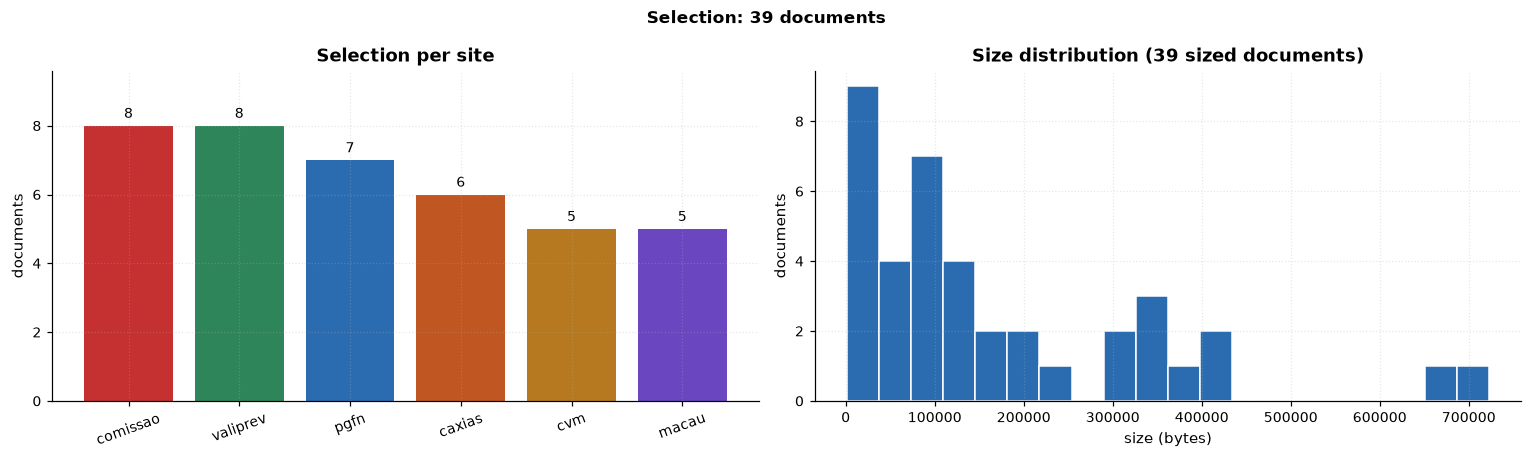

In [3]:
if df.empty:
    print("empty selection")
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
    cnt = df["site"].value_counts()
    axes[0].bar([d.short_site(s) for s in cnt.index], cnt.to_numpy(dtype=float), color=d.colors_for(cnt.index))
    axes[0].bar_label(axes[0].containers[0], padding=3, fontsize=9)
    axes[0].set_ylabel("documents")
    axes[0].set_title("Selection per site")
    axes[0].tick_params(axis="x", rotation=20)
    axes[0].set_ylim(0, cnt.max() * 1.2)

    sized = df.dropna(subset=["size"])
    if sized.empty:
        axes[1].text(0.5, 0.5, "no sizes published in this selection", ha="center", va="center")
        axes[1].set_axis_off()
    else:
        axes[1].hist(sized["size"], bins=20, color="#2b6cb0", edgecolor="white")
        axes[1].set_xlabel("size (bytes)")
        axes[1].set_ylabel("documents")
        axes[1].set_title(f"Size distribution ({len(sized)} sized documents)")
    fig.suptitle(f"Selection: {len(df)} documents", fontweight="bold")
    fig.tight_layout()
    plt.show()

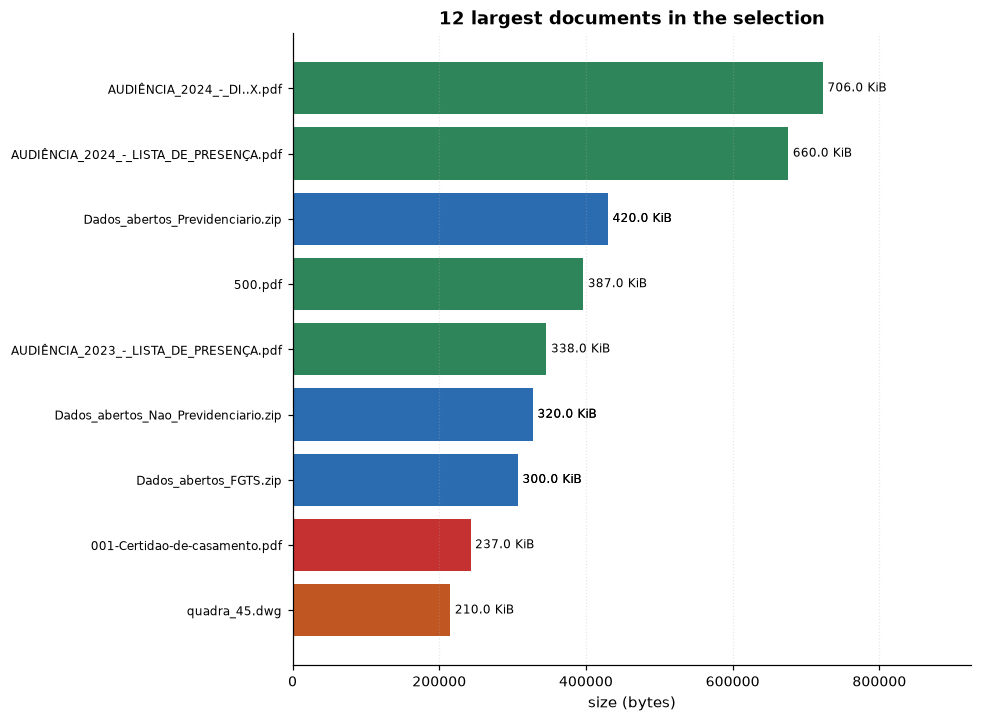

site,name,size,status,remote_mtime
valiprev.sp.gov.br,AUDIÊNCIA_2024_-_DI..X.pdf,706.0 KiB,downloaded,2024-10-30T14:28:00Z
valiprev.sp.gov.br,AUDIÊNCIA_2024_-_LISTA_DE_PRESENÇA.pdf,660.0 KiB,downloaded,2025-11-28T16:41:00Z
dadosabertos.pgfn.gov.br,Dados_abertos_Previdenciario.zip,420.0 KiB,duplicate,nan
dadosabertos.pgfn.gov.br,Dados_abertos_Previdenciario.zip,420.0 KiB,downloaded,nan
valiprev.sp.gov.br,500.pdf,387.0 KiB,downloaded,2024-11-18T11:15:00Z
valiprev.sp.gov.br,AUDIÊNCIA_2023_-_LISTA_DE_PRESENÇA.pdf,338.0 KiB,downloaded,2024-10-30T13:43:00Z
dadosabertos.pgfn.gov.br,Dados_abertos_Nao_Previdenciario.zip,320.0 KiB,downloaded,nan
dadosabertos.pgfn.gov.br,Dados_abertos_Nao_Previdenciario.zip,320.0 KiB,duplicate,nan
dadosabertos.pgfn.gov.br,Dados_abertos_FGTS.zip,300.0 KiB,duplicate,nan
dadosabertos.pgfn.gov.br,Dados_abertos_FGTS.zip,300.0 KiB,downloaded,nan


In [4]:
if df.empty or df["size"].isna().all():
    print("nothing sized to rank")
else:
    top = df.dropna(subset=["size"]).sort_values("size", ascending=False).head(TOP_N)
    fig, ax = plt.subplots(figsize=(9, 0.42 * len(top) + 1.6))
    t = top.iloc[::-1]
    bars = ax.barh(
        [n[:52] + ("…" if len(str(n)) > 52 else "") for n in t["name"]],
        t["size"].to_numpy(dtype=float),
        color=d.colors_for(t["site"]),
    )
    ax.bar_label(bars, labels=[d.human_bytes(v) for v in t["size"]], padding=3, fontsize=8)
    ax.set_xlabel("size (bytes)")
    ax.set_title(f"{len(t)} largest documents in the selection")
    ax.set_xlim(0, t["size"].max() * 1.28)
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    plt.show()

    display(
        top.assign(size=top["size"].map(d.human_bytes))[["site", "name", "size", "status", "remote_mtime"]]
        .reset_index(drop=True)
        .style.hide(axis="index")
    )

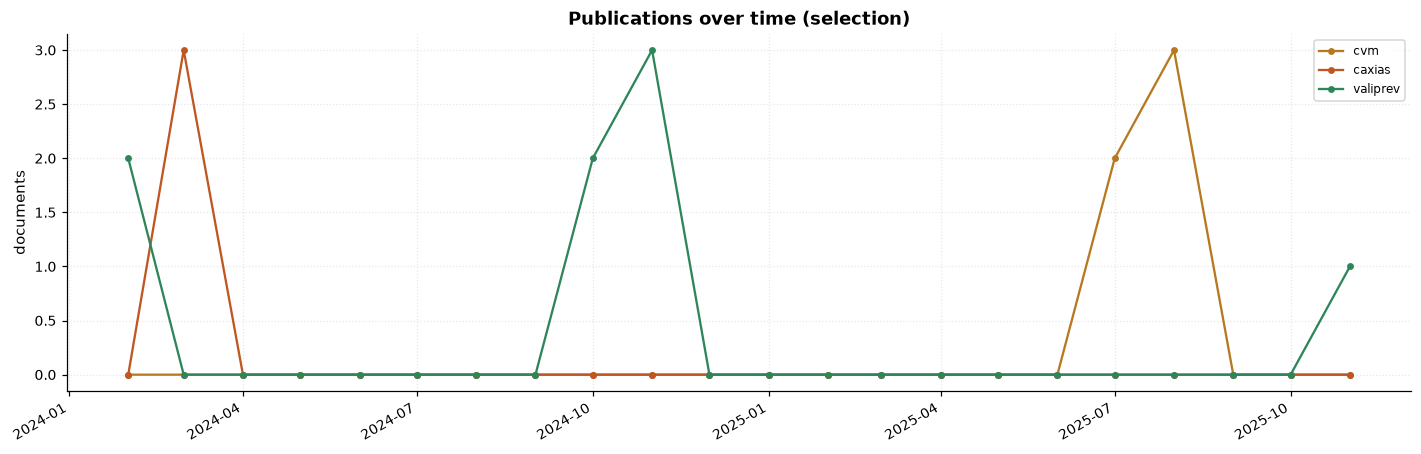

In [5]:
dated = df.dropna(subset=["mtime"])
if dated.empty:
    print("this selection has no publication dates to plot")
else:
    monthly = dated.set_index("mtime").groupby("site").resample("MS")["url"].count()
    wide = monthly.unstack(0).fillna(0)
    wide = wide.reindex(pd.date_range(wide.index.min(), wide.index.max(), freq="MS"), fill_value=0)

    fig, ax = plt.subplots(figsize=(13, 4.2))
    for site in wide.columns:
        ax.plot(wide.index, wide[site].to_numpy(dtype=float), marker="o", ms=3.5, label=d.short_site(site), color=d.colors_for([site])[0])
    ax.set_ylabel("documents")
    ax.set_title("Publications over time (selection)")
    ax.legend(fontsize=8)
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

In [6]:
# The raw selection, ready to copy into another notebook.
display(
    df.assign(size=df["size"].map(d.human_bytes))[
        [c for c in ("site", "name", "size", "status", "remote_mtime", "sha256", "url") if c in df.columns]
    ].reset_index(drop=True).head(40)
)

,site,name,size,status,remote_mtime,sha256,url
0,comissaodaverdade.al.sp.gov.br,001 - Ficha DEOPS Paulo Roberto Pinto.pdf,52.0 KiB,downloaded,NaN,4c45df4d047058ea699b2c6fa832123452d3eed84023f70122682efc03fe9fc2,https://replica.local/comissao/upload/001 - Ficha DEOPS Paulo Robe...
1,comissaodaverdade.al.sp.gov.br,001-Antonio-Raymundo-Lucena.pdf,140.0 KiB,downloaded,NaN,a807912f33c5b3062c9aaf616ee499cf285ed6b0f93ab8a70eb03e92a19325ee,https://replica.local/comissao/upload/001-Antonio-Raymundo-Lucena.pdf
2,comissaodaverdade.al.sp.gov.br,001-Arquivo-CEMDP-Joao-Carlos-Cavalcanti-Reis.pdf,88.0 KiB,downloaded,NaN,302000e3cd88caf65aaea50f53265ff46a02ec997790d14ae593695a227e600e,https://replica.local/comissao/upload/001-Arquivo-CEMDP-Joao-Carlo...
3,comissaodaverdade.al.sp.gov.br,001-Arquivo-CEMDP-Joao-Carlos-Cavalcanti-Reis004.pdf,88.0 KiB,duplicate,NaN,302000e3cd88caf65aaea50f53265ff46a02ec997790d14ae593695a227e600e,https://replica.local/comissao/upload/001-Arquivo-CEMDP-Joao-Carlo...
4,comissaodaverdade.al.sp.gov.br,001-ArquivoCEMDP-devanir.pdf,33.0 KiB,downloaded,NaN,c395464b53db3e9b4f1de7b32aee251e38e95236442ad8781680b0de586c00b1,https://replica.local/comissao/upload/001-ArquivoCEMDP-devanir.pdf
5,comissaodaverdade.al.sp.gov.br,001-ArquivoCEMDP.pdf,33.0 KiB,duplicate,NaN,c395464b53db3e9b4f1de7b32aee251e38e95236442ad8781680b0de586c00b1,https://replica.local/comissao/upload/001-ArquivoCEMDP.pdf
6,comissaodaverdade.al.sp.gov.br,001-CartaLilianRuggia1.jpg,76.0 KiB,downloaded,NaN,f8be19c93d07a88423ce8efad10cc06ea03fd6f57b2a209e0e5aa312473dd7f2,https://replica.local/comissao/upload/001-CartaLilianRuggia1.jpg
7,comissaodaverdade.al.sp.gov.br,001-Certidao-de-casamento.pdf,237.0 KiB,downloaded,NaN,698d66e90b821da2fbeb43124c7f0021d7cdfd1bd886fb6efb99d5aa5690df5f,https://replica.local/comissao/upload/001-Certidao-de-casamento.pdf
8,dados.cvm.gov.br,ADM_CART_CAD_2024.zip,64.0 KiB,downloaded,2025-07-11T18:23:00Z,2bc0e4689387cd29a2c7999be20f3ea07a4263ffde8b9c6ccd85453c7dd82ca9,https://replica.local/cvm/dados/ADM_CART/ADM_CART_CAD_2024.zip
9,dados.cvm.gov.br,ADM_CART_CAD_2025.zip,51.0 KiB,downloaded,2025-07-11T18:23:00Z,7fdb31a1b88731893b737a5585833dceb2b64aa62de20f0e624e91d6cd0b105a,https://replica.local/cvm/dados/ADM_CART/ADM_CART_CAD_2025.zip


## Things worth trying

* `TREE = "outputs"`, `SITES = ["valiprev.sp.gov.br"]` — the 53 real certificates,
  then set `MIN_BYTES = 1_000_000` to see only the heavy ones.
* `TREE = "outputs-replica"`, `STATUS = ["duplicate"]` — exactly the 9 collapses
  from notebook 03.
* `EXTENSIONS = [".zip"]` — the archive-shaped datasets (all of CVM and PGFN).
* `DATE_FROM = "2025-01-01"` with `TREE = "outputs"` — what was published recently
  versus what has been sitting there since 2024.